# Sesión 8 — Segmentación y detección de anomalías: aprender sin etiqueta

Hasta ahora, cada modelo aprendió de una **etiqueta**: el precio de una casa, la baja de un cliente.
Podíamos evaluar cada modelo porque conocíamos la respuesta verdadera de las filas de prueba. Esta
sesión quita la etiqueta. El **aprendizaje no supervisado** busca estructura solo en las variables:
qué columnas llevan la misma información, qué filas se parecen y qué filas son inusuales.

| | Aprendizaje supervisado | Aprendizaje no supervisado |
|---|---|---|
| **Datos** | variables y una etiqueta | solo variables |
| **Objetivo** | predecir la etiqueta de filas nuevas | encontrar estructura en los datos |
| **Evaluar el resultado** | comparar predicciones con etiquetas verdaderas | no hay respuesta verdadera con qué comparar |

La última fila es la pregunta de toda la sesión: **sin etiqueta, ¿cómo saber si funcionó?**

## Objetivos de aprendizaje

Al final de esta sesión podrán:

1. Explicar por qué muchas columnas hacen menos útiles las distancias — la **maldición de la
   dimensionalidad** — y distinguir **selección de variables** de **extracción de variables**.
2. Seleccionar variables por **relevancia** frente al objetivo y por **redundancia** entre variables,
   y explicar por qué la selección va dentro de la validación cruzada.
3. Explicar qué es una **componente principal**, por qué hay que escalar las variables antes del
   **PCA**, y cuántas componentes conservar.
4. Agrupar filas con **k-means**, y comparar un agrupamiento con una respuesta conocida mediante el
   **índice de Rand ajustado**.
5. Elegir el número de grupos con la **inercia** y la **estabilidad**, y nombrar sus límites.
6. Dibujar datos de muchas dimensiones con **UMAP**, y decir qué muestra y qué no muestra esa imagen.
7. Construir una **segmentación** de clientes sin respuesta correcta: comprobar que sea **estable** y
   **perfilarla** en términos de negocio.
8. Encontrar filas inusuales con una **regla de puntaje z** y con **Isolation Forest**, y explicar por
   qué no coinciden.

## Cómo está organizada la sesión

La sesión va de datos donde conocemos la respuesta a datos donde nadie la conoce. Los **vinos**
(secciones 1–6) y los **dígitos escritos a mano** (sección 7) tienen etiqueta. La selección de
variables la usa, como los métodos supervisados; los métodos no supervisados trabajan sin ella, y
solo la usamos después para comprobar el resultado. Los **turistas de invierno** (sección 8) no tienen
etiqueta, así que ahí decidimos con las herramientas de las secciones anteriores y con criterio de
negocio. La sección 9 prueba la detección de anomalías con puntos que colocamos nosotros.

> **Lectura más larga.** Esta sesión es breve a propósito. `8a-dimensionality_reduction.ipynb` y
> `8b-clustering_anomaly_detection.ipynb` explican las mismas ideas con más detalle, e incluyen temas
> que aquí quedan fuera: más métodos de selección, el clustering jerárquico y otras formas de
> evaluar un agrupamiento, como la silueta.

> **Qué necesitan de sesiones anteriores.** Estandarización y pipelines (sesión 2); validación
> cruzada, k vecinos más cercanos y líneas base (sesión 3); árboles de decisión (sesión 4); promediar
> muchos árboles aleatorios (sesión 5).

La celda siguiente importa todo lo que usa el notebook y fija una semilla aleatoria, que reutilizan
todas las celdas posteriores. `umap` es la única librería nueva; la sección 7 la presenta.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import adjusted_rand_score
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

## 1. Los datos

El conjunto **wine** contiene análisis químicos de vinos de una región de Italia (Forina et al., UCI
Machine Learning Repository).

- **178 filas y 13 columnas.** Una fila es un vino.
- **Cada columna es una medición química**, como el alcohol, la intensidad del color, el tono y la
  prolina (un aminoácido).
- **La etiqueta es el cultivar**: la variedad de uva, codificada como 0, 1 y 2.

Sirve para esta sesión porque los tres cultivares son grupos reales. Podemos ocultarlos, aplicar un
método y luego comprobar si el método los encontró.

La celda siguiente carga el archivo, separa la etiqueta en `y_wine`, e imprime el tamaño de la tabla y
el número de vinos por cultivar:

In [2]:
wine = pd.read_csv("wine.csv")
X_wine = wine.drop(columns="cultivar")
y_wine = wine["cultivar"]

print(f"{X_wine.shape[0]} vinos x {X_wine.shape[1]} mediciones")
print("vinos por cultivar:", y_wine.value_counts().sort_index().to_dict())
X_wine.head()

178 vinos x 13 mediciones
vinos por cultivar: {0: 59, 1: 71, 2: 48}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Las unidades son muy distintas: la prolina está en cientos o miles, mientras que el tono está cerca
de 1. Las distancias y las varianzas dependen de las unidades, así que los métodos de abajo
**estandarizan** las columnas primero, dentro de un pipeline, como en la sesión 2.

## 2. Distancias y la maldición de la dimensionalidad

Una fila con $p$ variables es un punto en un espacio de $p$ dimensiones; por eso el número de
variables también se llama **dimensionalidad** de los datos. Sin etiqueta, "filas parecidas" significa
"filas cercanas". La medida de cercanía habitual es la **distancia euclidiana**:

$$d(\mathbf{a}, \mathbf{b}) = \sqrt{\sum_{j=1}^{p} (a_j - b_j)^2}$$

donde:

- $\mathbf{a}$, $\mathbf{b}$ — dos filas, vistas como dos puntos.
- $p$ — el número de variables.
- $a_j$, $b_j$ — el valor de la variable $j$ en cada fila.
- $d(\mathbf{a}, \mathbf{b})$ — la distancia, desde $0$ (filas idénticas) hacia arriba.

La **maldición de la dimensionalidad** es el nombre de los problemas que crecen con el número de
dimensiones. El que importa aquí: **en muchas dimensiones, todos los puntos están casi a la misma
distancia entre sí**, así que "el más cercano" aporta poca información. Cada columna sin información
se suma a cada distancia y oculta las diferencias reales. `8a` mide el efecto en un modelo real.

La **reducción de dimensionalidad** describe los datos con menos columnas, conservando la información
que importa. Hay dos maneras de hacerlo:

| | Selección de variables | Extracción de variables |
|---|---|---|
| **Qué hace** | conserva algunas de las columnas originales | construye unas pocas columnas nuevas, cada una mezcla de todas las originales |
| **¿Fácil de explicar?** | sí — las columnas conservan su nombre | menos — una columna nueva no tiene un significado simple |
| **¿Usa la etiqueta?** | normalmente | no |
| **En esta sesión** | sección 3 | PCA (sección 4) y UMAP (sección 7) |

## 3. Selección de variables con correlaciones

Los métodos de selección forman tres familias. Los métodos **de filtro** puntúan cada columna con un
estadístico, antes de ajustar cualquier modelo. Los métodos **integrados** (*embedded*) dejan que un
modelo elija mientras entrena, por ejemplo con importancias de árboles o una penalización L1. Los
métodos **envolventes** (*wrapper*) ajustan un modelo con muchos subconjuntos de columnas y se quedan
con el mejor. `8a` muestra varios de ellos.

Esta sección usa dos filtros, ambos sobre cómo se mueven juntas las columnas:

1. **Relevancia** — qué tan fuerte es la relación de cada variable con el objetivo.
2. **Redundancia** — qué tan fuerte es la relación de las variables entre sí. Dos columnas que se
   mueven juntas llevan la misma información dos veces.

Un **pairplot** es una cuadrícula de gráficos, uno por cada par de columnas, y muestra las dos ideas a
la vez. La celda siguiente dibuja uno para cinco columnas de los vinos: las cuatro que discute esta
sección, más `magnesium` como contraste. Cada vino se colorea por su cultivar, y el nombre de columna
más largo se acorta a `od280`.

- **En la diagonal**, cada panel muestra cómo se distribuye una variable en cada cultivar. Curvas
  separadas indican una variable **relevante**.
- **Fuera de la diagonal**, cada panel enfrenta dos variables. Puntos a lo largo de una línea estrecha
  indican un par **redundante**.

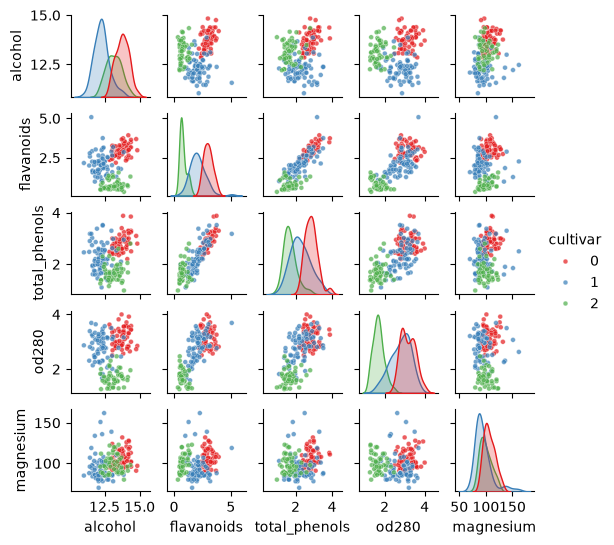

In [3]:
pairplot_columns = ["alcohol", "flavanoids", "total_phenols", "od280/od315_of_diluted_wines", "magnesium"]
sns.pairplot(
    wine[pairplot_columns + ["cultivar"]].rename(columns={"od280/od315_of_diluted_wines": "od280"}),
    hue="cultivar",
    palette="Set1",
    height=1.1,
    plot_kws={"s": 12, "alpha": 0.7},
)
plt.show()

Tres cosas para ver:

- **Relevancia.** En la diagonal de `flavanoids` los tres cultivares quedan separados; en la de
  `magnesium` se superponen. En la de `alcohol` también quedan separados, pero en el orden 1, 2, 0 —
  no 0, 1, 2. Recuérdenlo para los puntajes de abajo.
- **Redundancia.** `flavanoids` frente a `total_phenols` es una banda estrecha: conociendo una, casi se
  conoce la otra.
- **Dos variables que no se repiten.** `alcohol` frente a `flavanoids` separa los tres cultivares mejor
  que cualquiera de las dos sola. Por eso la selección mira la relevancia y la redundancia juntas.

### Relevancia: cada variable frente al objetivo

Para un objetivo numérico, el puntaje habitual es la **correlación de Pearson** $r$ de Fundamentos de
Ciencia de Datos: de $-1$ a $1$, mide qué tan cerca están dos columnas de una relación en línea recta.
Pero el cultivar es una **categoría**. Sus códigos 0, 1 y 2 son nombres, no cantidades, y otra
codificación daría otro $r$. La versión para clases de la misma pregunta es el **estadístico F**:
¿están lejos entre sí las medias de una variable en cada clase, comparadas con la dispersión dentro
de cada clase?

$$F = \frac{\sum_{g=1}^{G} n_g (\bar{x}_g - \bar{x})^2 \;/\; (G - 1)}{\sum_{g=1}^{G} \sum_{i \in g} (x_i - \bar{x}_g)^2 \;/\; (n - G)}$$

donde:

- $G$ — el número de clases, aquí $3$; $n$ — el número de filas.
- $n_g$ — el número de filas de la clase $g$.
- $x_i$ — el valor de la variable en la fila $i$.
- $\bar{x}_g$ — la media de la variable en la clase $g$; $\bar{x}$ — su media en todas las filas.
- $F$ — $0$ o más. El numerador mide qué tan lejos están las medias de clase de la media general; el
  denominador mide la dispersión dentro de las clases. **Mayor significa una variable más relevante.**

> **En `scikit-learn`.** `f_classif(X, y)` devuelve el estadístico F de cada columna (y valores p, que
> aquí no usamos). Para un objetivo numérico, `r_regression(X, y)` devuelve el $r$ de Pearson.

La celda siguiente calcula el estadístico F de cada variable y, para comparar, $|r|$ con los códigos
0, 1, 2, y ordena las variables según ambos:

In [4]:
f_scores, _ = f_classif(X_wine, y_wine)
relevance = pd.DataFrame(
    {
        "F": f_scores,
        "|r| con códigos": X_wine.corrwith(y_wine).abs().to_numpy()
    },
    index=X_wine.columns,
)
relevance["posición por F"] = relevance["F"].rank(ascending=False).astype(int)
relevance["posición por |r|"] = relevance["|r| con códigos"].rank(ascending=False).astype(int)
relevance.sort_values("posición por F").round(2)

,F,|r| con códigos,posición por F,posición por |r|
flavanoids,233.93,0.85,1,1
proline,207.92,0.63,2,4
od280/od315_of_diluted_wines,189.97,0.79,3,2
alcohol,135.08,0.33,4,10
color_intensity,120.66,0.27,5,11
hue,101.32,0.62,6,5
total_phenols,93.73,0.72,7,3
malic_acid,36.94,0.44,8,9
alcalinity_of_ash,35.77,0.52,9,6
proanthocyanins,30.27,0.50,10,7


Los dos puntajes ponen primero a `flavanoids`. Pero `alcohol` queda **4°** por F y **10°** por
$|r|$, y `color_intensity` queda 5° y 11°, respectivamente. La celda siguiente muestra por qué,
con la media de ambas variables en cada cultivar:

In [5]:
X_wine.groupby(y_wine)[["alcohol", "color_intensity"]].mean().round(2)

,alcohol,color_intensity
cultivar,,
0,13.74,5.53
1,12.28,3.09
2,13.15,7.40


La media de alcohol **baja y luego sube** a lo largo de los códigos del cultivar: 13,74, 12,28, 13,15. Las clases
difieren claramente, pero no en línea recta a través de 0, 1, 2, así que $r$ no ve lo que F sí ve.
**En conclusión, usen un puntaje que corresponda al tipo de objetivo.**

La celda siguiente muestra lo mismo con diagramas de caja: la distribución de cada variable en cada
cultivar:

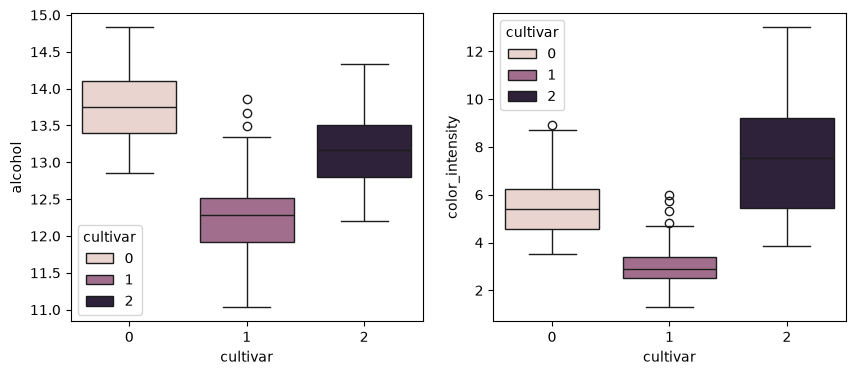

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(x=y_wine, y=X_wine["alcohol"], ax=axes[0], hue=y_wine)
sns.boxplot(x=y_wine, y=X_wine["color_intensity"], ax=axes[1], hue=y_wine)
plt.show()

En `alcohol` el cultivar 0 está arriba, el 1 abajo y el 2 en medio: el orden es 1, 2, 0. En
`color_intensity` el 1 está abajo, el 0 en medio y el 2 arriba. Las cajas se separan bien, pero no en
el orden de los códigos.

### Redundancia: variables entre sí

La celda siguiente calcula la correlación $r$ entre cada par de variables:

In [7]:
feature_corr = X_wine.corr()

La celda siguiente la dibuja como mapa de calor: rojo es correlación positiva, azul negativa, y la
diagonal es cada variable consigo misma:

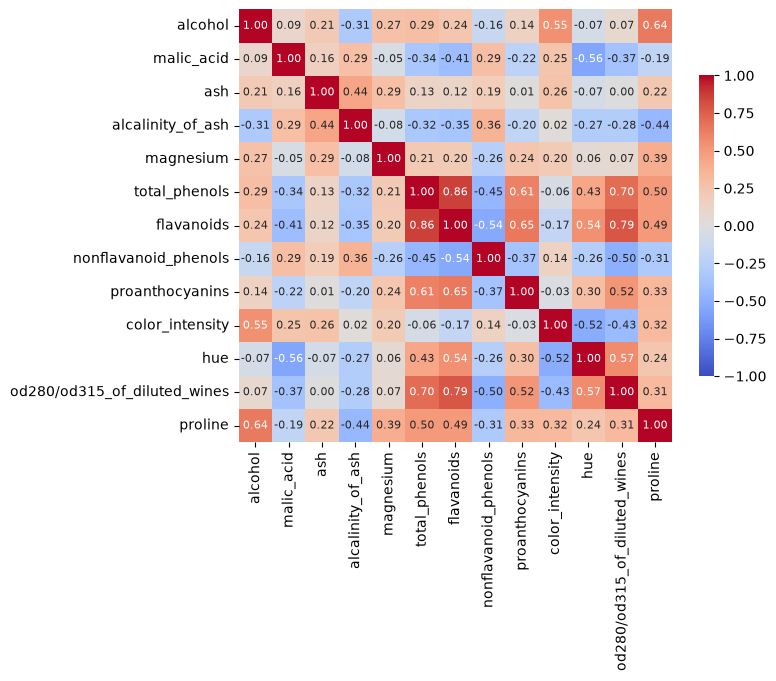

In [8]:
plt.figure(figsize=(8, 8))
sns.heatmap(
    feature_corr,
    annot=True, fmt=".2f", annot_kws={"size": 8},
    cmap="coolwarm", cbar_kws={"shrink": 0.5},
    center=0, vmin=-1, vmax=1,
    square=True,
)
plt.tight_layout()
plt.show()

Fuera de la diagonal, los rojos más intensos son `total_phenols` con `flavanoids` (0,86) y
`flavanoids` con `od280/od315_of_diluted_wines` (0,79).

La celda siguiente toma $|r|$ y lista los pares por encima de 0,75:

In [9]:
upper_triangle = np.triu(np.ones(feature_corr.shape, dtype=bool), k=1)
pairs = feature_corr.abs().where(upper_triangle).stack().dropna().sort_values(ascending=False)
pairs[pairs > 0.75].round(3)

total_phenols  flavanoids                      0.865
flavanoids     od280/od315_of_diluted_wines    0.787
dtype: float64

`total_phenols` y `flavanoids` correlacionan **0,865** — los flavanoides son un tipo de fenol, así que
las dos columnas miden casi lo mismo. `flavanoids` y `od280/od315_of_diluted_wines` correlacionan
**0,787**.

Un filtro de relevancia solo conservaría estas dos últimas: son 1.° y 3.° por F, y sin
embargo se repiten. Una regla común combina los dos filtros: **de cada par muy correlacionado,
conservar la variable más relevante para el objetivo** — aquí, `flavanoids`.

> **Todo paso ajustado va dentro de la validación cruzada — y los pasos que usan la etiqueta son los
> que más filtran.** El filtro de redundancia solo usa las variables, como un escalador o el PCA. El
> filtro de relevancia, y nuestra regla de desempate por relevancia, usan la etiqueta. Ajustados con
> todas las filas, dejan que las filas de prueba decidan qué columnas sobreviven. Pongan el selector
> en el pipeline, para que se ajuste solo con los pliegues de entrenamiento. `8a` mide cuán optimista
> se vuelve el puntaje si no.
>
> **En `scikit-learn`.** `SelectKBest(f_classif, k=...)` conserva las `k` columnas con mayor F.

## 4. Análisis de componentes principales

El **análisis de componentes principales (PCA)** es el método de extracción de variables más común.
Construye columnas nuevas, llamadas **componentes principales**. Cada una es una suma ponderada de las
variables originales estandarizadas:

$$z_k = w_{k1} x_1 + w_{k2} x_2 + \dots + w_{kp} x_p$$

donde:

- $z_k$ — el valor de la componente $k$ para una fila: su posición sobre un eje nuevo.
- $x_1, \dots, x_p$ — los valores estandarizados de las variables de esa fila.
- $w_{k1}, \dots, w_{kp}$ — los **pesos** (o **cargas**) de la componente $k$. Dan la dirección del eje
  nuevo.
- $p$ — el número de variables originales, que también es el número de componentes.

El PCA elige los pesos para que la primera componente tenga la **mayor varianza posible**: apunta en
la dirección en que los datos se dispersan más. Cada componente siguiente es **no correlacionada** con
las anteriores y toma la mayor varianza que queda. La proporción de la varianza total que lleva una
componente es su **proporción de varianza explicada**:

$$\text{EVR}_k = \frac{\operatorname{var}(z_k)}{\operatorname{var}(z_1) + \dots + \operatorname{var}(z_p)}$$

donde:

- $\operatorname{var}(z_k)$ — la varianza de la componente $k$.
- $\text{EVR}_k$ — entre $0$ y $1$; las proporciones de las $p$ componentes suman $1$.

Conservar solo las primeras componentes conserva casi toda la varianza con menos columnas. El PCA nunca
mira la etiqueta, así que es un método no supervisado.

**Estandaricen antes del PCA.** El PCA busca la mayor varianza, y la varianza depende de las unidades:
sin escalar, la columna con los números más grandes decide la primera componente, mida lo que mida.
`8a` lo muestra con datos reales.

> **En `scikit-learn`.** `PCA(n_components=...)`; tras ajustar, `explained_variance_ratio_` guarda las
> proporciones y `components_` los pesos, una fila por componente. El signo de una componente es
> arbitrario.

La celda siguiente ajusta un pipeline que estandariza los vinos y aplica PCA con las 13 componentes.
Dibuja dos paneles: a la izquierda, la proporción de varianza de cada componente; a la derecha, el
acumulado. Fíjense en qué tan rápido cae el panel izquierdo, y dónde el derecho cruza 90 % y 95 %:

In [23]:
wine_pca = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA()),
]).fit(X_wine)
wine_pca


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('pca', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['alcohol','malic_acid','ash',...,'hue','od280/od315_of_diluted_wines', 'proline']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


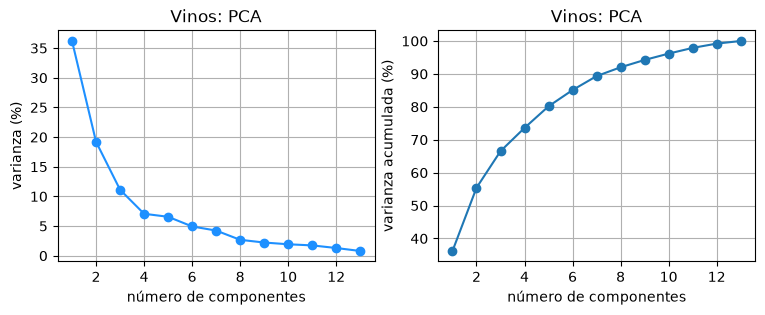

In [24]:

evr = wine_pca["pca"].explained_variance_ratio_
evr_cumulative = np.cumsum(evr)

fig, ax = plt.subplots(figsize=(9, 3), nrows=1, ncols=2,)
ax[0].plot(range(1, len(evr) + 1), 100 * evr, marker="o", c="dodgerblue")
ax[0].set(xlabel="número de componentes", ylabel="varianza (%)", title="Vinos: PCA")
ax[0].grid(True)
ax[1].plot(range(1, len(evr) + 1), 100 * evr_cumulative, marker="o")
ax[1].set(xlabel="número de componentes", ylabel="varianza acumulada (%)", title="Vinos: PCA")
ax[1].grid(True)
plt.show()

El panel izquierdo muestra que la primera componente lleva cerca del **36 %** de la varianza y la
segunda cerca del **19 %**; desde la cuarta, cada una agrega cerca de 7 % o menos. El panel derecho
cruza el 90 % con **ocho** componentes y el 95 % con **diez**. Una regla común conserva componentes
hasta el 90–95 %. Pero varianza no es lo mismo que utilidad: el PCA nunca vio la etiqueta, así que una
componente pequeña puede importar para una predicción.

> **El PCA es un paso ajustado, así que puede filtrar información.** Como un escalador, el PCA aprende
> de las filas con que se ajusta. Ajustado con todas las filas antes de dividir, deja que las filas de
> prueba moldeen las componentes. Pónganlo **dentro del pipeline**, después del escalador, para que la
> validación cruzada lo ajuste solo con los pliegues de entrenamiento. En los vinos la diferencia es
> demasiado pequeña para medirla; la regla de la sesión 2 se mantiene igual.

### Dibujar los vinos

Dos componentes se pueden dibujar en un plano. La celda siguiente proyecta los vinos estandarizados
sobre las dos primeras componentes, imprime la varianza que conservan, y los dibuja dos veces: a la
izquierda sin etiqueta, todos en gris; a la derecha coloreados por cultivar. Busquen grupos primero en
el panel izquierdo y luego compárenlos con el derecho:

varianza conservada por 2 componentes: 55.4%


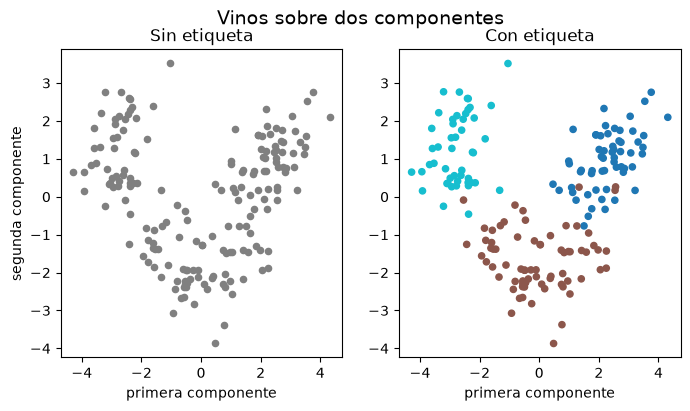

In [26]:
wine_2d = wine_pca.transform(X_wine)[:, :2]
print(f"varianza conservada por 2 componentes: {evr[:2].sum():.1%}")

fig, ax = plt.subplots(figsize=(8, 4), nrows=1, ncols=2)
fig.suptitle('Vinos sobre dos componentes', fontsize=14)
ax[0].scatter(wine_2d[:, 0], wine_2d[:, 1], color="grey", s=20)
ax[0].set(title="Sin etiqueta", xlabel="primera componente", ylabel="segunda componente")
ax[1].scatter(wine_2d[:, 0], wine_2d[:, 1], c=y_wine, cmap="tab10", s=20)
ax[1].set(title="Con etiqueta", xlabel="primera componente")
plt.show()

Las dos componentes conservan el **55,4 %** de la varianza, así que es solo parte de la imagen. Aun
así, los puntos no forman una nube pareja: forman una banda curva con tres zonas más densas. Al
colorear por cultivar, cada zona es casi solo una variedad de uva, con algunos vinos en los bordes. El
PCA nunca vio la etiqueta, y aun así dos componentes ya separan los cultivares; la comparación de abajo
mide qué tan bien. Con datos reales solo tenemos el panel izquierdo. La sección 5 encuentra estos
grupos con un método.

¿Qué mide cada eje? La celda siguiente muestra el peso de cada variable original en las dos primeras
componentes: rojo es un peso positivo, azul negativo:

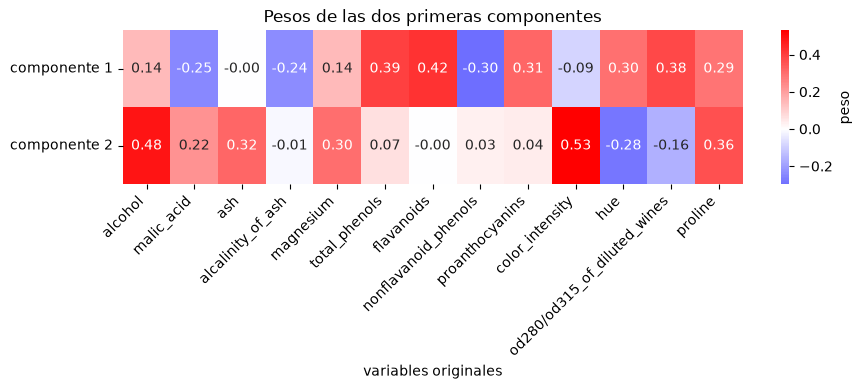

In [12]:
wine_2d_components = pd.DataFrame(
    data=wine_pca.named_steps["pca"].components_[:2, :],
    index=["componente 1", "componente 2"],
    columns=wine_pca.feature_names_in_,
)

plt.figure(figsize=(10, 2), dpi=100)
sns.heatmap(
    wine_2d_components,
    annot=True,
    fmt=".2f",
    cmap="bwr",
    center=0,
    annot_kws={"size": 10},
    cbar_kws={"label": "peso"},
)
plt.xticks(rotation=45, ha="right")
plt.title("Pesos de las dos primeras componentes")
plt.xlabel("variables originales")
plt.ylabel("")
plt.show()

La primera componente pesa sobre todo `flavanoids` (0,42), `total_phenols` (0,39) y `od280` (0,38),
frente a `nonflavanoid_phenols` (−0,30) y `malic_acid` (−0,25): resume la química de los fenoles. La
segunda pesa sobre todo `color_intensity` (0,53) y `alcohol` (0,48). Recuerden que el signo de una
componente es arbitrario: lo que importa es qué variables pesan juntas.

### ¿Selección o extracción?

Ahora comparamos las dos estrategias con 5 vecinos más cercanos, con cada paso dentro del pipeline. La
celda siguiente imprime las dos referencias: la línea base, que siempre predice el cultivar más común,
y el modelo con las 13 columnas:

In [27]:
baseline_scores = cross_val_score(DummyClassifier(), X_wine, y_wine, cv=5)
all_columns = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])
all_scores = cross_val_score(all_columns, X_wine, y_wine, cv=5)
print(f"línea base:     exactitud {baseline_scores.mean():.3f}")
print(f"13 columnas:    exactitud {all_scores.mean():.3f} +/- {all_scores.std():.3f}")

línea base:     exactitud 0.399
13 columnas:    exactitud 0.949 +/- 0.038


La celda siguiente aplica validación cruzada, para $k$ = 1, 2, 3 y 5, a las $k$ mejores variables
según F y a las primeras $k$ componentes principales:

In [14]:
rows = []
for k in [1, 2, 3, 5]:
    selection = Pipeline([
        ("scale", StandardScaler()),
        ("select", SelectKBest(f_classif, k=k)),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
    ])
    extraction = Pipeline([
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=k)),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
    ])
    rows.append({
        "columnas conservadas": k,
        "selección: k mejores por F": cross_val_score(selection, X_wine, y_wine, cv=5).mean(),
        "extracción: k componentes": cross_val_score(extraction, X_wine, y_wine, cv=5).mean(),
    })
pd.DataFrame(rows).set_index("columnas conservadas").round(3)

,selección: k mejores por F,extracción: k componentes
columnas conservadas,,
1,0.680,0.844
2,0.838,0.966
3,0.922,0.938
5,0.961,0.961


La línea base obtiene **0,399** y las 13 columnas **0,949** (±0,038). Con una o dos columnas, la
extracción va muy por delante — **0,844** frente a **0,680**, y **0,966** frente a **0,838** — porque
cada componente mezcla las 13 columnas, mientras que una columna seleccionada solo se lleva a sí misma.
Con cinco columnas ambas llegan a **0,961**, tan bien como las 13 dentro de la dispersión. La
selección conserva columnas que el negocio puede leer; la extracción mete más información en cada
columna. **Cuál gana depende de los datos y del uso del resultado: mídanlo.**

## 5. Agrupamiento con k-means

El **agrupamiento** (*clustering*) reparte las filas en grupos, llamados **clústeres**, de modo que las
filas de un mismo clúster estén cerca y las de clústeres distintos estén lejos.

**k-means** divide las filas en $k$ clústeres, donde $k$ es un número que elegimos. Cada clúster tiene
un **centroide**, la media de sus filas:

$$\mathbf{c}_j = \frac{1}{n_j} \sum_{i \in C_j} \mathbf{x}_i$$

donde:

- $\mathbf{x}_i$ — la fila $i$, vista como un punto.
- $C_j$ — el conjunto de filas del clúster $j$, y $n_j$ — cuántas filas tiene.
- $\mathbf{c}_j$ — el centroide del clúster $j$, para $j = 1, \dots, k$.

La **inercia** mide qué tan cerca están las filas de su propio centroide:

$$\text{inercia} = \sum_{i=1}^{n} d(\mathbf{x}_i, \mathbf{c}_{(i)})^2$$

donde:

- $n$ — el número de filas.
- $\mathbf{c}_{(i)}$ — el centroide del clúster al que pertenece la fila $i$.
- $d$ — la distancia euclidiana de la sección 2.
- $\text{inercia}$ — $0$ o más; menor significa que las filas están más cerca de sus centroides.

k-means baja la inercia con un ciclo: elegir $k$ filas al azar como primeros centroides; **asignar**
cada fila a su centroide más cercano; **actualizar** cada centroide a la media de sus filas; repetir
los dos últimos pasos hasta que nada cambie. El resultado depende del inicio aleatorio, así que el
método arranca varias veces y se queda con la menor inercia. `8b` escribe este ciclo a mano.

> **En `scikit-learn`.** `KMeans(n_clusters=3, n_init=10, random_state=...)`. `n_init` es el número
> de arranques; `fit_predict` devuelve el clúster de cada fila; `inertia_` guarda la inercia. Los
> números de clúster 0, 1, 2 no significan nada: otra ejecución puede numerar los mismos clústeres de
> otra forma.

La celda siguiente ajusta un escalador y k-means con $k = 3$ en un pipeline, e imprime la inercia y el
número de vinos por clúster:

In [15]:
wine_kmeans = Pipeline([
    ("scale", StandardScaler()),
    ("cluster", KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)),
])
wine_clusters = wine_kmeans.fit_predict(X_wine)

print(f"inercia: {wine_kmeans['cluster'].inertia_:,.1f}")
print("vinos por clúster:", np.bincount(wine_clusters).tolist())

inercia: 1,277.9
vinos por clúster: [65, 51, 62]


La celda siguiente dibuja la misma imagen de dos componentes de antes, ahora coloreada por clúster de k-means:

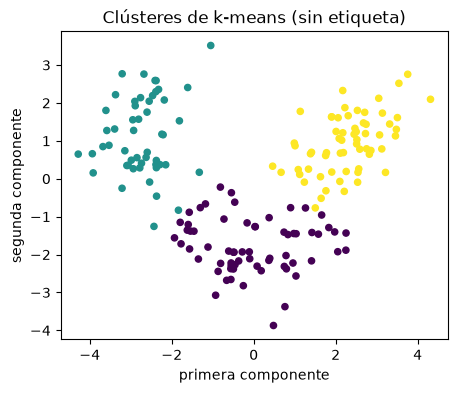

In [16]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(wine_2d[:, 0], wine_2d[:, 1], c=wine_clusters, cmap="viridis", s=20)
ax.set(title="Clústeres de k-means (sin etiqueta)", xlabel="primera componente", ylabel="segunda componente")
plt.show()

k-means dividió la banda en tres grupos, uno en cada zona densa.

### Comparar con la etiqueta oculta

Ahora usamos la etiqueta de cultivar que ocultamos. Para comparar dos agrupamientos con un solo número usamos el
**índice de Rand ajustado (ARI)**. Mira cada **par** de filas y pregunta si los dos agrupamientos
coinciden: juntas en ambos, o separadas en ambos. Ignora los números de clúster, y está **ajustado**
para que grupos al azar obtengan cerca de 0.

- **ARI = 1**: los dos agrupamientos son idénticos.
- **ARI ≈ 0**: coinciden lo mismo que coincidirían grupos al azar.

> **En `scikit-learn`.** `adjusted_rand_score(labels_a, labels_b)`.

La celda siguiente cruza clústeres con cultivares:

In [17]:
print(pd.crosstab(y_wine, pd.Series(wine_clusters, name="clúster")).to_string())

clúster    0   1   2
cultivar            
0          0   0  59
1         65   3   3
2          0  48   0


Cada clúster tiene casi un solo cultivar; solo **6** vinos quedan fuera del clúster de su cultivar.

La celda siguiente imprime el ARI de los clústeres y, como referencia, el de grupos al azar:

In [18]:
random_groups = np.random.default_rng(RANDOM_STATE).integers(0, 3, size=len(y_wine))
print(f"clústeres de k-means vs cultivar: ARI = {adjusted_rand_score(y_wine, wine_clusters):.3f}")
print(f"grupos al azar vs cultivar:       ARI = {adjusted_rand_score(y_wine, random_groups):.3f}")

clústeres de k-means vs cultivar: ARI = 0.897
grupos al azar vs cultivar:       ARI = -0.006


El ARI es **0,897**, frente a **−0,006** para grupos al azar. **Sin ver la etiqueta, k-means encontró
las tres variedades de uva.**

La celda siguiente muestra las dos cosas en una imagen: el color es el cultivar verdadero y la forma
del marcador es el clúster de k-means:

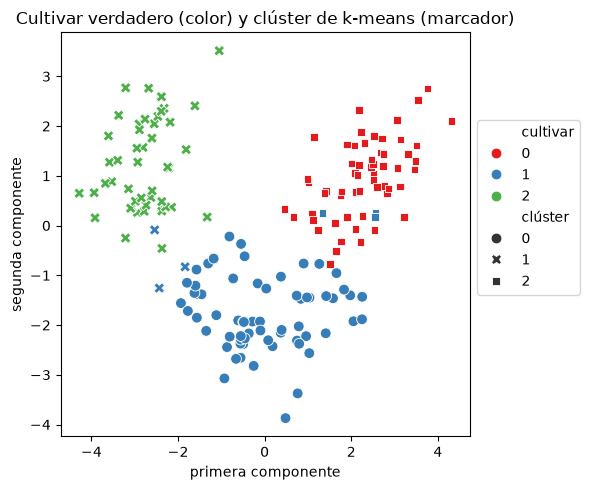

In [19]:
fig_data = pd.DataFrame(data=wine_2d, columns=["primera componente", "segunda componente"])
fig_data["cultivar"] = y_wine
fig_data["clúster"] = wine_clusters

fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(
    x="primera componente",
    y="segunda componente",
    data=fig_data,
    hue="cultivar",
    style="clúster",
    palette="Set1",
    s=60,
    ax=ax,
)
ax.set_title("Cultivar verdadero (color) y clúster de k-means (marcador)")
ax.legend(bbox_to_anchor=(1, 0.8), loc="upper left")
fig.tight_layout()
plt.show()

Color y marcador coinciden casi en todas partes. Los 6 vinos que no coinciden son del cultivar 1 y
están en los bordes de su zona, donde toca a las otras dos. Pero solo pudimos comprobar todo esto
porque teníamos la etiqueta. La sección siguiente evalúa un agrupamiento sin ella.

## 6. ¿Cuántos clústeres?

Elegimos $k = 3$ porque sabíamos que hay tres cultivares. Normalmente no lo sabemos. Un **índice de
validez** puntúa un agrupamiento usando solo los datos, así que podemos probar varios valores de $k$ y
comparar.

La **inercia** siempre baja cuando $k$ crece — más centroides significa que cada fila tiene uno más
cerca — así que su menor valor no es la meta. El **método del codo** busca el $k$ a partir del cual la
inercia deja de bajar rápido.

La inercia se basa en distancias a un centro, así que favorece clústeres **compactos y redondos**.
Un grupo alargado y curvo puede ser un grupo real y aun así puntuar mal.

> Hay otros índices de validez, como la silueta, Calinski–Harabasz y Davies–Bouldin; `8b` los
> explica.

La sección 8 necesita el mismo análisis, así que la celda siguiente define una función que ejecuta
k-means para cada $k$ y devuelve su inercia:

In [28]:
def validity_indexes(X: pd.DataFrame, k_values: range) -> pd.DataFrame:
    """Ejecuta k-means para cada número de clústeres y devuelve su inercia.

    Args:
        X: Los datos preparados, una fila por punto.
        k_values: Los números de clústeres a probar.

    Returns:
        Una fila por número de clústeres, con su inercia.
    """
    rows = []
    for k in k_values:
        clusters = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
        rows.append({
            "k": k,
            "inercia": clusters.inertia_,
        })
    return pd.DataFrame(rows).set_index("k")

La celda siguiente estandariza los vinos, puntúa $k$ de 2 a 8, y dibuja la inercia:

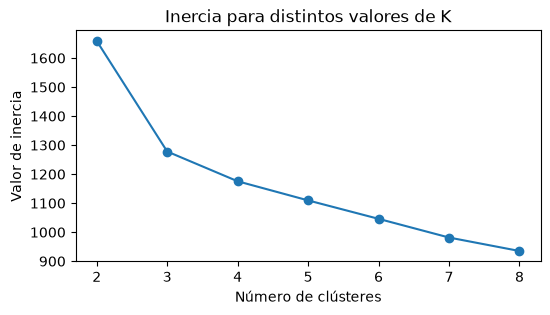

In [29]:
X_wine_preproc = StandardScaler().set_output(transform="pandas").fit_transform(X_wine)
wine_validity = validity_indexes(X_wine_preproc, range(2, 9))

wine_validity.plot(figsize=(6, 3), marker="o", legend=False)
plt.title("Inercia para distintos valores de K")
plt.xlabel("Número de clústeres")
plt.ylabel("Valor de inercia")
plt.show()

La inercia baja rápido de $k = 2$ a $k = 3$ y despacio después: el codo está en $k = 3$, el número real
de cultivares. Con grupos reales el codo se ve; con datos de encuestas, como en la sección 8, casi
nunca.

## 7. Dibujar datos de muchas dimensiones: PCA y UMAP

El PCA es bueno para comprimir datos para un modelo. Es menos bueno para **dibujarlos**, porque solo
puede rotar los ejes y descartar algunos. Esta sección lo compara con un método hecho para dibujar.

### Los datos de dígitos

El conjunto **digits** contiene imágenes pequeñas de dígitos escritos a mano por 43 personas (UCI
Optical Recognition of Handwritten Digits).

- **1.797 filas y 64 columnas.** Una fila es una imagen de **8 × 8 píxeles**; cada columna es un
  píxel, de 0 (vacío) a 16 (totalmente oscuro).
- **La etiqueta es el dígito mostrado**, de 0 a 9, con unas 180 imágenes de cada uno.

Sirve para esta sección porque 64 dimensiones no se pueden dibujar directamente, y los diez dígitos son
grupos conocidos con los que podemos comprobar una imagen. Todas las columnas son píxeles en las mismas
unidades, así que no hace falta escalar.

La celda siguiente carga el archivo, imprime su tamaño y muestra la primera imagen de cada dígito:

1797 imágenes x 64 píxeles


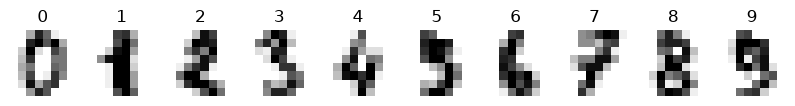

In [32]:
digits = pd.read_csv("digits.csv")
X_digits = digits.drop(columns="digit")
y_digits = digits["digit"]
print(f"{X_digits.shape[0]} imágenes x {X_digits.shape[1]} píxeles")

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for digit, ax in enumerate(axes):
    first_row = np.flatnonzero(y_digits == digit)[0]
    ax.imshow(X_digits.iloc[first_row].to_numpy().reshape(8, 8), cmap="gray_r")
    ax.set_title(str(digit))
    ax.axis("off")
plt.show()

### Cómo funciona UMAP

**UMAP** (Uniform Manifold Approximation and Projection) es **no lineal**: sus ejes nuevos no son sumas
ponderadas de las columnas. Trabaja en dos pasos:

1. **Construir un grafo de vecinos.** En las 64 dimensiones originales, conectar cada imagen con sus
   vecinas más cercanas.
2. **Desplegar el grafo en dos dimensiones**, moviendo los puntos paso a paso para que las imágenes
   conectadas queden cerca y las no conectadas queden lejos.

UMAP conserva **vecindarios** — quién está cerca de quién — no las distancias mismas. Esto funciona
pese a la sección 2 porque los datos reales no son aleatorios: las imágenes no llenan las 64
dimensiones, sino que están cerca de una forma mucho más simple, una **variedad** (*manifold*), y cerca
de ella los vecinos más cercanos siguen significando algo.

Su parámetro principal es el **tamaño de vecindario**: con cuántos vecinos se conecta cada punto.
Valores pequeños conservan el detalle local; valores grandes muestran la estructura más amplia. El
inicio es aleatorio, así que fijamos una semilla.

> **En `umap-learn`.** `umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42, n_jobs=1)`, con el
> `fit_transform` de siempre. Fijar `random_state` obliga a usar un solo procesador; `n_jobs=1` lo
> declara y evita una advertencia. La primera ejecución es lenta porque la librería compila su código.
> También verán **t-SNE**, un método más antiguo para lo mismo; las reglas de lectura de abajo también
> valen para él.

Dibujamos los dígitos varias veces, así que la celda siguiente define una función que colorea cada
punto según su dígito y escribe el dígito en el centro de su grupo:

In [33]:
def plot_embedding(embedding: np.ndarray, labels: pd.Series, title: str, ax: plt.Axes) -> None:
    """Dibuja una proyección de dos dimensiones con un color por dígito.

    Args:
        embedding: Arreglo con una fila por imagen y dos columnas.
        labels: El dígito que muestra cada imagen.
        title: Título del gráfico.
        ax: Los ejes donde dibujar.
    """
    for digit in range(10):
        rows = (labels == digit).to_numpy()
        ax.scatter(embedding[rows, 0], embedding[rows, 1], s=4, alpha=0.6, color=plt.cm.tab10(digit))
        middle = np.median(embedding[rows], axis=0)
        ax.text(*middle, str(digit), fontsize=12, fontweight="bold", ha="center", va="center",
                bbox={"boxstyle": "circle", "facecolor": "white", "alpha": 0.85})
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

La celda siguiente reduce los 64 píxeles a dos dimensiones dos veces — con PCA y con UMAP — y dibuja
las dos imágenes lado a lado. Las etiquetas de dígito se usan solo para los colores. También imprime la
varianza que conserva el PCA:

varianza conservada por 2 componentes de PCA: 28.5%


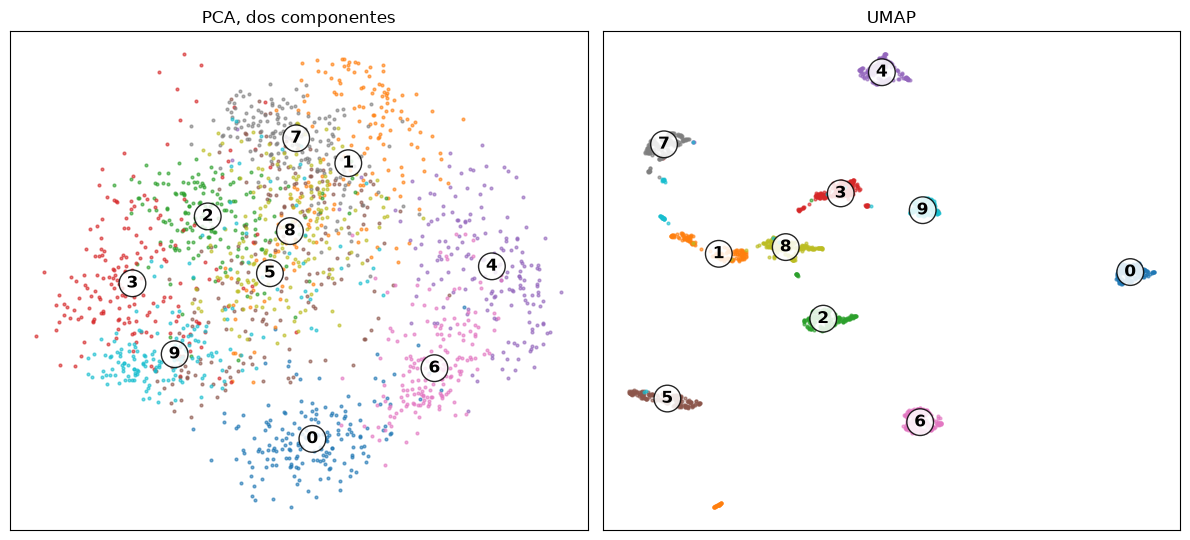

In [34]:
digits_pca = PCA(n_components=2).fit(X_digits)
print(f"varianza conservada por 2 componentes de PCA: {digits_pca.explained_variance_ratio_.sum():.1%}")

digits_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE, n_jobs=1).fit_transform(X_digits)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
plot_embedding(digits_pca.transform(X_digits), y_digits, "PCA, dos componentes", axes[0])
plot_embedding(digits_umap, y_digits, "UMAP", axes[1])
plt.tight_layout()
plt.show()

El PCA conserva el **28,5 %** de la varianza. Algunos dígitos tienen su propia zona en el borde, pero
la mayoría se superponen en el centro. UMAP separa los diez dígitos en grupos, y nunca vio las
etiquetas.

### Leer una imagen de UMAP

Las imágenes de UMAP invitan a conclusiones equivocadas. Tres reglas:

1. **El tamaño de un grupo no significa nada.** UMAP extiende algunos grupos y comprime otros.
2. **Las distancias entre grupos no son confiables.** Dos grupos lejanos no son necesariamente más
   distintos que dos grupos cercanos.
3. **Distintos parámetros dan distintas imágenes.** Confíen solo en lo que se mantiene al cambiarlos.

La celda siguiente muestra la regla 3. Dibuja los dígitos con un tamaño de vecindario de 5 y de 100:

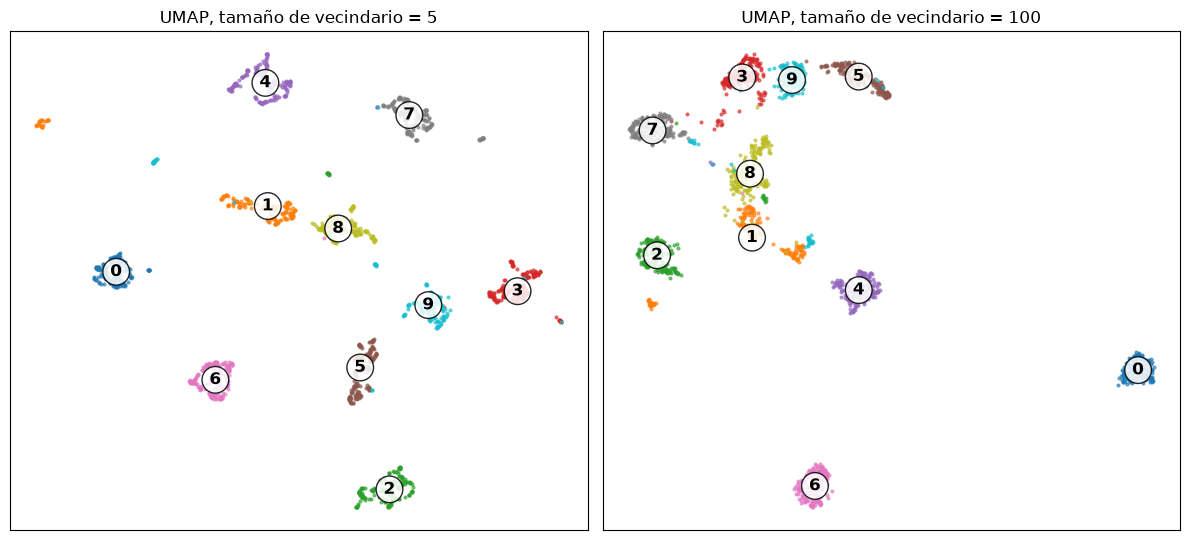

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for n_neighbors, ax in zip([5, 100], axes):
    embedding = umap.UMAP(n_neighbors=n_neighbors, min_dist=0.1, random_state=RANDOM_STATE, n_jobs=1).fit_transform(X_digits)
    plot_embedding(embedding, y_digits, f"UMAP, tamaño de vecindario = {n_neighbors}", ax)
plt.tight_layout()
plt.show()

En ambas imágenes cada dígito forma su propio grupo — esa es la parte confiable. Lo que cambia es
dónde quedan los grupos y qué tan lejos están, que las reglas 1 y 2 dicen no leer.

**Usen PCA** cuando el resultado alimenta un modelo: es rápido, repetible, y sus pesos se pueden leer.
**Usen UMAP** cuando el resultado es una imagen para personas: conserva vecindarios que una proyección
lineal mezcla.

## 8. Segmentación de clientes: sin respuesta correcta

La **segmentación de clientes** divide a los clientes de una empresa en unos pocos grupos, llamados
**segmentos**, que la empresa trata de forma distinta. Aquí no hay etiqueta oculta. Nadie conoce los
segmentos "verdaderos".

### Los datos de turistas de invierno

La **Austrian National Guest Survey** preguntó a turistas de vacaciones de invierno en Austria qué
actividades hicieron durante su estadía; la organización nacional de turismo usó las respuestas para
planificar su marketing. Los datos vienen con el libro *Market Segmentation Analysis* (Dolnicar, Grün
y Leisch, 2018), que los usa para la misma tarea.

- **2.961 filas y 27 columnas.** Una fila es un turista, en el invierno de 1997/98.
- **Cada columna es una actividad**, como esquí alpino, salir a caminar o hacer turismo.
- **Cada valor es 1 o 0**: el turista hizo la actividad, o no.
- Algunas actividades necesitan explicación: **carving** es un estilo de esquí alpino, los
  **heurigen** son tabernas de vino austriacas, y las **noches tirolesas** (*tyrolean evenings*) son
  espectáculos de música y baile tradicional.

El script `data/prepare_winter_activities.py` descargó el archivo desde el sitio web del libro.

La celda siguiente lo carga, imprime su tamaño y muestra los primeros cinco turistas:

In [37]:
activities = pd.read_csv("winter_activities.csv")
print(f"{activities.shape[0]} turistas x {activities.shape[1]} actividades")
activities.head()

2961 turistas x 27 actividades


,alpine skiing,cross-country skiing,snowboarding,carving,ski touring,ice-skating,sleigh riding,tennis,horseback riding,going to a spa,...,going to discos/bars,shopping,sight-seeing,museums,theater/opera,heurigen,concerts,tyrolean evenings,local events,pool/sauna
0,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
1,1,0,0,0,0,1,1,0,0,1,...,0,0,1,1,0,0,0,0,0,1
2,0,0,0,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,1
3,1,0,0,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,1,...,0,1,1,1,0,0,0,0,0,1


La celda siguiente cuenta las actividades de cada turista e imprime la mediana:

In [38]:
activities_per_tourist = activities.sum(axis=1)
print(f"mediana de actividades por turista: {activities_per_tourist.median():.0f}")

mediana de actividades por turista: 6


El turista mediano hizo **6** actividades.

La celda siguiente dibuja la proporción de turistas que hizo cada actividad, de la más común (arriba) a
la más rara (abajo):

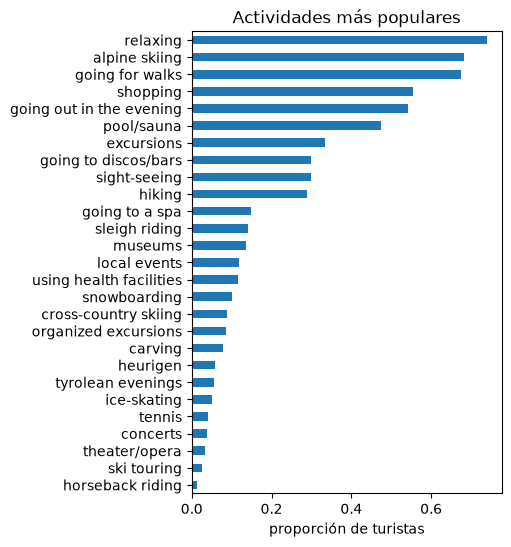

In [39]:
(
    activities.mean()
    .sort_values(ascending=True)
    .plot(kind="barh", figsize=(4, 6), title="Actividades más populares")
)
plt.xlabel("proporción de turistas")
plt.show()

Descansar, el esquí alpino y salir a caminar son las más comunes, con cerca del 70 % de los turistas;
teatro/ópera, ski touring y cabalgar son las más raras, con menos del 5 %.

**Aquí no se escala.** Cada columna es 0 o 1, así que todas las columnas ya comparten una escala. Con
datos sí/no, la distancia euclidiana al cuadrado de la sección 2 tiene un significado simple: cada
término vale 1 cuando las respuestas de dos turistas difieren y 0 cuando coinciden, así que **cuenta
las actividades en las que dos turistas difieren**. Un centroide también es fácil de leer: para cada
actividad, la media de ceros y unos es la **proporción** de turistas del clúster que la hizo.

### ¿Cuántos segmentos?

La celda siguiente ejecuta la misma función que con los vinos, para $k$ de 2 a 8, y dibuja la inercia:

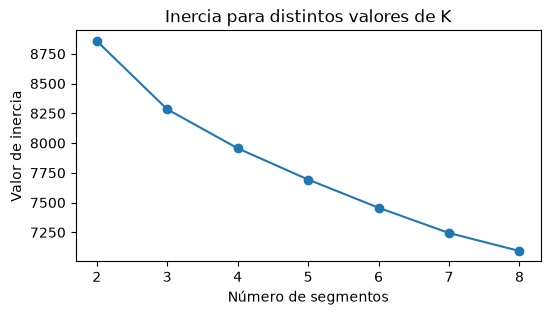

In [40]:
activity_validity = validity_indexes(activities, range(2, 9))

activity_validity.plot(figsize=(6, 3), marker="o", legend=False)
plt.title("Inercia para distintos valores de K")
plt.xlabel("Número de segmentos")
plt.ylabel("Valor de inercia")
plt.show()

La inercia baja suavemente, sin codo claro. **Los turistas reales no forman grupos claramente
separados**, así que los índices no pueden decidir solos.

### Estabilidad

Una pregunta más ayuda cuando los grupos son débiles: **¿es estable el agrupamiento?** k-means arranca
al azar. Una segmentación con la que una empresa pueda planificar no debe cambiar cuando se vuelve a
ejecutar el método desde otros arranques. Comparamos dos ejecuciones con el ARI de la sección 5: 1
significa que ambas hicieron exactamente los mismos segmentos.

La celda siguiente define una función que ejecuta k-means con 10 semillas para cada $k$ y compara cada
ejecución con la primera, y luego la aplica a los turistas:

In [41]:
def stability(X: pd.DataFrame, k_values: range, n_seeds: int) -> pd.DataFrame:
    """Ejecuta k-means con varias semillas para cada número de clústeres y compara las ejecuciones.

    Args:
        X: Los datos preparados, una fila por punto.
        k_values: Los números de clústeres a probar.
        n_seeds: Cuántas ejecuciones, cada una con otra semilla, para cada número de clústeres.

    Returns:
        Una fila por número de clústeres con el ARI mínimo y el ARI medio entre la primera
        ejecución y cada una de las demás.
    """
    rows = []
    for k in k_values:
        first_run = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
        aris = []
        for seed in range(RANDOM_STATE + 1, RANDOM_STATE + n_seeds):
            other_run = KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(X)
            aris.append(adjusted_rand_score(first_run, other_run))
        rows.append({"k": k, "ARI mínimo": min(aris), "ARI medio": np.mean(aris)})
    return pd.DataFrame(rows).set_index("k")


stability(activities, range(2, 9), n_seeds=10).round(2)

,ARI mínimo,ARI medio
k,,
2,1.00,1.00
3,1.00,1.00
4,0.53,0.74
5,0.39,0.52
6,0.33,0.64
7,0.37,0.57
8,0.33,0.46


Para $k = 2$ y $k = 3$ todas las ejecuciones dan los mismos segmentos (ARI 1,00). Desde $k = 4$, los
segmentos cambian con la semilla: el ARI medio es **0,65** en $k = 4$ y **0,39** en $k = 8$.

Así que la elección está entre 2 y 3. Dos segmentos dividen a los turistas más o menos en esquiadores y
no esquiadores, lo que es poco para un equipo de marketing. Elegimos **$k = 3$**: es estable, y el
perfil de abajo muestra que lleva a tres acciones distintas. **Los índices y la estabilidad acotan la
elección; el propósito de la segmentación la decide.**

### Perfilar los segmentos

**Perfilar** es describir cada segmento en términos de negocio: su tamaño, qué hace su cliente típico,
y en qué se diferencia del cliente promedio.

La celda siguiente ajusta k-means con $k = 3$ y guarda el segmento de cada turista en una tabla nueva,
`tourists` (así `activities` no cambia):

In [ ]:
segmentation = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
tourists = activities.assign(segmento=segmentation.fit_predict(activities))

La celda siguiente muestra el tamaño, la proporción y la mediana de actividades de cada segmento:

In [ ]:
pd.DataFrame({
    "turistas por segmento": tourists["segmento"].value_counts(sort=False),
    "proporción de turistas": tourists["segmento"].value_counts(sort=False, normalize=True).round(2),
    "mediana de actividades por turista": tourists.groupby("segmento").apply(lambda x: x.sum(axis=1).median())
})

Los segmentos tienen 1.233, 901 y 827 turistas, con medianas de 6, 4 y 8 actividades.

La celda siguiente construye el **perfil**: para cada segmento, la proporción de sus turistas que hizo
cada actividad, junto a la proporción entre todos los turistas, como mapa de calor en porcentaje. Se
lee comparando la columna de cada segmento con la última:

In [ ]:
profile = tourists.groupby("segmento").mean().T
profile.columns = [f"segmento {j}" for j in profile.columns]
profile["todos los turistas"] = activities.mean()

fig, ax = plt.subplots(figsize=(6, 9))
sns.heatmap(profile * 100, annot=True, fmt=".0f", cmap="viridis", cbar_kws={"label": "% de turistas"}, ax=ax)
ax.set(title="Proporción de turistas que hizo cada actividad (%)")
plt.show()

| Segmento | Tamaño | Perfil | Acción |
|---|---|---|---|
| 0: **esquiadores que caminan** | 1.233 (42 %) | esquía (82 %), y todos salen a caminar (100 %); mediana de 6 actividades | agregar senderos de invierno y lugares tranquilos a las vacaciones de esquí |
| 1: **solo esquiadores** | 901 (30 %) | es el que más esquía (90 %); nadie sale a caminar (0 %); mediana de 4 actividades | vender pases y paquetes de esquí |
| 2: **turistas culturales** | 827 (28 %) | esquía poco (24 % frente a 68 %); turismo 85 %, excursiones 81 %, museos 43 %; mediana de 8 actividades | promover excursiones, museos y eventos culturales |

Noten qué separa a los segmentos 0 y 1: sobre todo **una** actividad, salir a caminar. Con datos sí/no,
k-means a menudo divide un grupo grande según una actividad común. La división es real y estable, pero
menor que la diferencia entre esquiadores y turistas culturales. **Una segmentación se valida según si
sus segmentos significan algo y llevan a acciones distintas, no por un índice.**

## 9. Detección de anomalías

Una **anomalía** (o **valor atípico**) es una fila muy distinta de la mayoría. La **detección de
anomalías** encuentra esas filas sin etiqueta. Una anomalía puede ser un error en los datos o un caso
raro pero real: un pago fraudulento, una máquina que falla.

Para comprobar los métodos de nuevo necesitamos una respuesta conocida, así que la fabricamos. La celda
siguiente genera **200 puntos normales** de una distribución normal estándar (media 0, desviación
estándar 1) en dos columnas, y **planta 4 puntos**: el punto 200 lejos solo en `x`, el punto 201 lejos
solo en `y`, y los puntos 202 y 203 lejos en **ambas** columnas a la vez, pero menos lejos en cada una
por separado. Los dibuja con los puntos plantados en rojo:

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
planted = np.array([[5.5, 0.5], [0.3, -5.5], [-3.0, 3.0], [3.0, -3.0]])
points = pd.DataFrame(np.vstack([rng.normal(size=(200, 2)), planted]), columns=["x", "y"])
is_planted = points.index >= 200

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(points.loc[~is_planted, "x"], points.loc[~is_planted, "y"], s=12, color="grey")
ax.scatter(points.loc[is_planted, "x"], points.loc[is_planted, "y"], s=50, color="red")
for i in points.index[is_planted]:
    ax.annotate(str(i), (points.loc[i, "x"], points.loc[i, "y"]), xytext=(5, 4), textcoords="offset points")
ax.set(title="200 puntos normales y 4 plantados", xlabel="x", ylabel="y")
ax.set_aspect("equal")
plt.show()

### Línea base: la regla del puntaje z

El método más simple usa el **puntaje z** de la sesión 2:

$$z = \frac{x - \bar{x}}{s}$$

donde:

- $x$ — el valor de una fila en una columna.
- $\bar{x}$, $s$ — la media y la desviación estándar de esa columna.
- $z$ — cuántas desviaciones estándar está el valor por encima ($z > 0$) o por debajo ($z < 0$) de la
  media.

La regla marca una fila cuando **alguna** columna tiene $|z| > 3$. La celda siguiente la aplica y
muestra los puntajes z de los puntos plantados:

In [ ]:
z_scores = StandardScaler().set_output(transform="pandas").fit_transform(points)
z_flags = (z_scores.abs() > 3).any(axis=1)

print(f"puntos marcados por la regla del puntaje z: {z_flags.sum()}")
z_scores[is_planted].round(2).assign(marcado=z_flags[is_planted])

La regla marca solo los puntos 200 y 201. Se le escapan el 202 y el 203, cuyos puntajes z quedan justo
por debajo de 3 en cada columna. Mira **una columna a la vez**, así que no puede ver que estar lejos en
ambas columnas juntas es inusual.

### Isolation Forest

**Isolation Forest** parte de una idea: una fila inusual es **fácil de aislar** del resto. Construye
**árboles de aislamiento**, que dividen los datos como los árboles de decisión de la sesión 4, pero sin
etiqueta y con divisiones **aleatorias**: una columna al azar y un umbral al azar entre su mínimo y su
máximo. Un árbol sigue dividiendo hasta que cada fila queda sola.

- Una fila dentro de la multitud necesita **muchas** divisiones para quedar sola.
- Una fila lejos de las demás queda sola tras **pocas** divisiones.

Un solo árbol aleatorio es ruidoso, así que el método promedia muchos árboles, como hicieron los
bosques aleatorios de la sesión 5. Pocas divisiones en promedio significa un **puntaje de anomalía**
alto. El método da puntajes, no decisiones: para marcar filas elegimos la **contaminación**, la
proporción de filas a marcar. Esa proporción la elegimos nosotros; los datos no la dicen.

> **En `scikit-learn`.** `IsolationForest(n_estimators=100, contamination=0.02, random_state=...)`.
> `fit_predict` devuelve `-1` para una anomalía y `1` para una fila normal. `score_samples` devuelve
> puntajes donde **menor** significa más inusual, así que cambiamos el signo.

La celda siguiente ejecuta Isolation Forest con una contaminación del 2 % y lista cada punto marcado o
plantado con su puntaje, su posición y las marcas de ambos métodos:

In [ ]:
isolation_forest = IsolationForest(n_estimators=100, contamination=0.02, random_state=RANDOM_STATE)
forest_flags = isolation_forest.fit_predict(points) == -1
anomaly_score = -isolation_forest.score_samples(points)

print(f"puntos marcados por Isolation Forest: {forest_flags.sum()}")
pd.DataFrame({
    "plantado": is_planted,
    "puntaje de anomalía": anomaly_score.round(3),
    "posición": pd.Series(anomaly_score).rank(ascending=False).astype(int),
    "marca puntaje z": z_flags,
    "marca Isolation Forest": forest_flags,
})[forest_flags | is_planted]

Isolation Forest marca **5** puntos. Los cuatro plantados tienen los cuatro puntajes más altos,
incluidos el 202 y el 203, que la regla del puntaje z no vio. La quinta marca es un punto normal en el
borde de la nube: el 2 % de 204 puntos pide 5 marcas, así que se marca un punto normal. **Sin
etiqueta, la contaminación decide cuántas alarmas recibimos** — y con datos reales, alguien tiene que
revisar cada una.

La celda siguiente dibuja las marcas de ambos métodos lado a lado. Los puntos marcados están en rojo;
los demás en gris:

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)
axes[0].scatter(points["x"], points["y"], c=z_flags.astype(int), cmap="Set1_r")
axes[0].set(title=f"Regla del puntaje z ({z_flags.sum()} marcados)", xlabel="x", ylabel="y")
axes[1].scatter(points["x"], points["y"], c=forest_flags.astype(int), cmap="Set1_r")
axes[1].set(title=f"Isolation Forest ({forest_flags.sum()} marcados)", xlabel="x")
plt.tight_layout()
plt.show()

La regla del puntaje z solo detecta los puntos extremos en una columna. Isolation Forest mira ambas
columnas juntas y detecta los cuatro puntos plantados, más un punto normal en el borde.

# Cierre

## Qué estableció esta sesión

- **Sin etiqueta, no hay puntaje con qué comparar.** Cada sección respondió *¿cómo saber si funcionó?*
  de una forma distinta: una etiqueta oculta en datos controlados, índices de validez, estabilidad y
  significado de negocio.
- **Muchas columnas perjudican a los métodos basados en distancias**, así que las reducimos: la
  **selección** conserva columnas originales, la **extracción** construye columnas nuevas.
- **El puntaje de selección debe corresponder al objetivo.** Para el cultivar, el estadístico F puso a
  `alcohol` 4.°; la correlación con los códigos de clase lo puso 10.°. Los **pares redundantes**, como
  `total_phenols` y `flavanoids` (0,865), llevan la misma información dos veces. Todo paso ajustado va
  dentro del pipeline, y los pasos que usan la etiqueta son los que más filtran.
- **El PCA** construye componentes no correlacionadas, ordenadas por varianza. **Estandaricen
  primero**, porque la varianza depende de las unidades. Es un paso ajustado, así que va dentro del
  pipeline.
- **Cuál reducción gana depende de los datos.** Con dos columnas, el PCA obtuvo 0,966 y la selección
  0,838; con cinco, ambas igualaron a las 13 columnas.
- **k-means** encontró los tres cultivares sin verlos (ARI 0,897). **La inercia** mostró un
  codo en $k = 3$ ahí; con los turistas no hubo codo.
- **UMAP** dibuja vecindarios. Lean qué puntos se agrupan; nunca lean el tamaño de los grupos ni las
  distancias entre ellos.
- **Una segmentación real se elige por estabilidad y propósito.** Solo $k = 2$ y $k = 3$ fueron
  estables, y tres segmentos dieron tres acciones distintas.
- **Isolation Forest** mira todas las columnas juntas y detectó los puntos que la regla del puntaje z,
  columna por columna, no vio. Su contaminación es una decisión, no un hallazgo.

## Qué no hizo esta sesión

- **La selección integrada y envolvente**, y una medición de la maldición de la dimensionalidad, están
  en `8a`.
- **El clustering jerárquico**, la silueta, los índices de Calinski–Harabasz y Davies–Bouldin, y escribir k-means a
  mano están en `8b`.
- Varios parámetros se eligieron a mano: el número de componentes, $k$, la contaminación. La sesión 6
  buscaba parámetros cuando había un puntaje que optimizar. Sin etiqueta no hay tal puntaje, y por eso
  cada decisión aquí se apoyó en la estabilidad y en el uso del resultado.